### Imports

In [1]:
!which python
%pip install --upgrade pip
%pip install uproot
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install torch
%pip install scikit-learn
%pip install torchviz
!source /opt/homebrew/bin/thisroot.sh
!root --version

/Users/krishwu/.local/share/virtualenvs/WhitesonAIModelDistinguisher-zmfe64jY/bin/python
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
ROOT Version: 6.32.06
Built for macosxarm64 on Sep 21 2024, 18:21:53
From tags/6-32-06@6-32-06


In [2]:
import uproot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score, RocCurveDisplay, auc
from sklearn.neural_network import MLPClassifier
from torchviz import make_dot

### Import Data

In [3]:
data = pd.read_csv("data/v5/data.csv")

data = data.to_numpy()

indices = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25])

dataLabels = data[:,26:]
data = data[:,indices]

data = StandardScaler().fit_transform(data)

pt = np.array([[item[0]] for item in data])
# dataLabels = np.array([item[0] for item in dataLabels])

data.shape
dataLabels.shape

(47440, 1)

In [4]:
# split data
X_train_numpy, X_test_numpy, y_train_numpy, y_test_numpy = train_test_split(data, dataLabels, test_size=0.25, random_state=123)
X_train = torch.tensor(X_train_numpy, dtype=torch.float32)
X_test = torch.tensor(X_test_numpy, dtype=torch.float32)
y_train = torch.tensor(y_train_numpy, dtype=torch.float32)
y_test = torch.tensor(y_test_numpy, dtype=torch.float32)

In [5]:
# pt_scaled = StandardScaler().fit_transform(pt)
X = torch.tensor(data, dtype=torch.float32)
XOnlyPt = torch.tensor(pt, dtype=torch.float32)
y = torch.tensor(dataLabels, dtype=torch.float32).reshape(-1, 1)

In [6]:
for i in range(10):
    print(data[i])

print(X.shape, y.shape, X_train.shape, y_train.shape)

[ 0.54103403 -0.21216089  0.7066582  -1.40040401  0.25281093  0.64272419
  1.18102547  2.63115556  1.2993018   0.09553383 -3.64225432 -0.36124852
  1.08649474  0.58793824  0.03080151 -0.12749042  0.68669026  0.87405129
  0.63090601 -0.12749042 -0.74397317  0.91076065 -0.91494305  0.2316128
  0.20076979]
[-0.71446276  1.71238703 -0.40596384 -0.11658624  2.25272567  1.71237732
  1.45714418  0.17046923  3.19442406 -1.11187248  0.32244252  3.59935581
  3.50283339  3.64739343 -0.69947613 -0.92618474  0.29371318 -0.3309315
  0.05094352 -0.92618474 -0.24341371  2.22614408 -0.78018301  1.04462107
  3.39198808]
[-0.34683538 -0.39358819  0.63005898 -0.42658249 -0.65309634 -0.4236261
 -0.18301983 -0.74803125  0.26809069 -0.09389028 -0.21635534 -1.15576096
  0.04027504 -0.49792846 -0.32033033 -0.64547123  0.728847   -0.31002173
  0.07695037 -0.64547123  0.4185398   0.25292296  0.55605379  1.06490523
 -0.29584954]
[ 1.80526601  0.65230886 -1.25550056  2.41949853 -0.12535645  0.57724136
  0.53311814

### Logistic Regression

In [9]:
clf = LogisticRegression(random_state=123)
clf.fit(X_train_numpy, y_train_numpy)

/Users/krishwu/.local/share/virtualenvs/WhitesonAIModelDistinguisher-zmfe64jY/lib/python3.12/site-packages/sklearn/utils/validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression(random_state=123)

In [10]:
y_pred = clf.predict(X_test_numpy)

acc = accuracy_score(y_test_numpy, y_pred)
print("Logistic Regression model accuracy (in %):", acc*100)

Logistic Regression model accuracy (in %): 82.43676222596964


In [11]:
confusion_matrix(y_test_numpy, y_pred)

array([[5164,  791],
       [1292, 4613]])

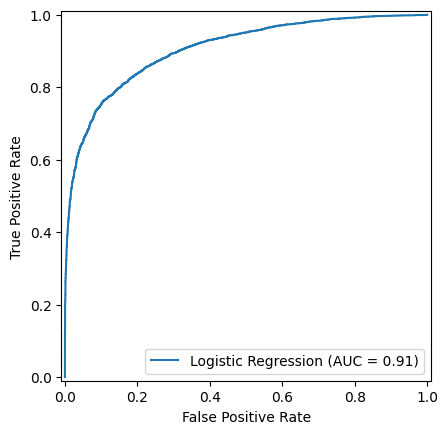

In [12]:
y_prob = clf.predict_proba(X_test_numpy)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test_numpy, y_prob)

roc_auc = auc(fpr, tpr)

display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="Logistic Regression")
display.plot()

plt.show()

### Neural Network (from Website)

### Neural Network (from Website)

In [59]:
for i in range(10):
    print(X_test[:, 1].shape)

torch.Size([11860])
torch.Size([11860])
torch.Size([11860])
torch.Size([11860])
torch.Size([11860])
torch.Size([11860])
torch.Size([11860])
torch.Size([11860])
torch.Size([11860])
torch.Size([11860])


In [67]:
dataColLabelNames = ["HeavyTParticle_Pt", "HeavyTParticle_P", "HeavyTParticle_Px", "HeavyTParticle_Py", "HeavyTParticle_Pz", "HeavyTParticle_E", "HeavyTParticle_M",
    "TParticle_Pt", "TParticle_P", "TParticle_Px", "TParticle_Py", "TParticle_Pz", "TParticle_E", "TParticle_M",
    "Photon_Pt", "Photon_P", "Photon_Px", "Photon_Py", "Photon_Pz", "Photon_E", "Photon_M",
    "HeavyTParticlePhotonDelta", "TwoQuarkDelta", "TParticlePhotonDelta", "math.pow((tParticle.P() + heavyTParticle.P()), 2)", "isDim6"]

for modelNum in range(21):
    torch.manual_seed(124)

    model = nn.Sequential(
        nn.Linear(1, 100),
        nn.ReLU(),
        nn.Linear(100, 80),
        nn.ReLU(),
        nn.Linear(80, 20),
        nn.ReLU(),
        nn.Linear(20, 1),
        nn.Sigmoid()
    )

    # Create loss function and optimizer
    loss_fn = nn.BCELoss() # binary cross entropy
    optimizer = optim.Adam(model.parameters())
    
    tempXTrain = torch.tensor([[x] for x in X_train[:, modelNum]])
    tempXTest = torch.tensor([[x] for x in X_test[:, modelNum]])

    print(tempXTrain.shape, y_train.shape, tempXTest.shape, y_test.shape)

    y_prediction = model(tempXTest)

    n_epochs = 1
    batch_size = 10
    lossesTrain = []
    lossesTest = []

    # Train the model
    for epoch in range(n_epochs):
        for i in range(0, len(X_train), batch_size):
            model.train()
            Xbatch = tempXTest[i:i+batch_size]
            # Xbatch = X
            ybatch = y_train[i:i+batch_size]
            # ybatch = y
            y_prediction = model(Xbatch)
            print(y_prediction.shape, ybatch.shape)
            loss = loss_fn(y_prediction, ybatch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            model.eval()
            y_pred = model(tempXTest)
            lossTest = loss_fn(y_pred, y_test)

            lossesTrain.append(loss.detach().numpy())
            lossesTest.append(lossTest.detach().numpy())

    y_prob = model(X_test)
    fpr, tpr, thresholds = roc_curve(y_test.numpy(), y_prob.detach().numpy())
    roc_auc = auc(fpr, tpr)

    print(dataColLabelNames[modelNum], roc_auc)


torch.Size([35580, 1]) torch.Size([35580, 1]) torch.Size([11860, 1]) torch.Size([11860, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Size([10, 1])
torch.Size([10, 1]) torch.Si

ValueError: Using a target size (torch.Size([10, 1])) that is different to the input size (torch.Size([0, 1])) is deprecated. Please ensure they have the same size.

Finished epoch 0, latest loss 0.41097599267959595, 0.3811211884021759
Finished epoch 1, latest loss 0.39528003334999084, 0.3807537257671356


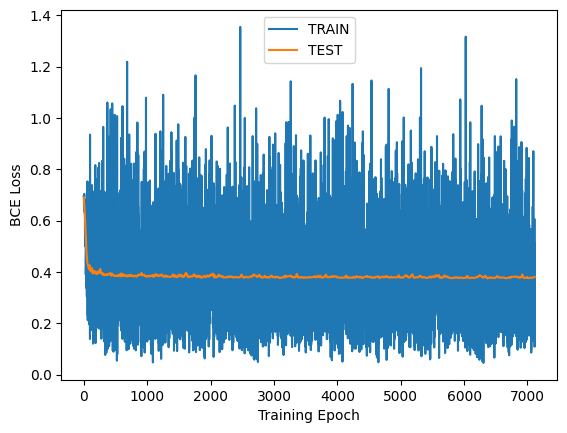

In [ ]:
# compute accuracy (no_grad is optional)
with torch.no_grad():
    y_prediction = model(X_train)

accuracy = (y_prediction.round() == y_train).float().mean()
print(f"Accuracy (train) {accuracy}")

Accuracy (train) 0.8352445363998413


In [ ]:
# compute accuracy (no_grad is optional)
with torch.no_grad():
    y_prediction = model(X_test)

for i in range(20):
    print(y_test[i], y_prediction[i])

accuracy = (y_prediction.round() == y_test).float().mean()
print(f"Accuracy (test) {accuracy}")

tensor([0.]) tensor([0.1816])
tensor([1.]) tensor([0.9983])
tensor([1.]) tensor([0.9995])
tensor([1.]) tensor([0.9670])
tensor([0.]) tensor([0.0522])
tensor([1.]) tensor([0.8742])
tensor([1.]) tensor([0.9957])
tensor([1.]) tensor([1.0000])
tensor([1.]) tensor([0.7915])
tensor([1.]) tensor([0.9880])
tensor([1.]) tensor([0.0871])
tensor([1.]) tensor([0.2061])
tensor([0.]) tensor([0.1577])
tensor([1.]) tensor([0.5377])
tensor([1.]) tensor([1.0000])
tensor([0.]) tensor([0.8252])
tensor([0.]) tensor([0.0933])
tensor([0.]) tensor([0.2116])
tensor([1.]) tensor([0.9342])
tensor([1.]) tensor([0.9916])
Accuracy (test) 0.8295109868049622


0.9086510528085678


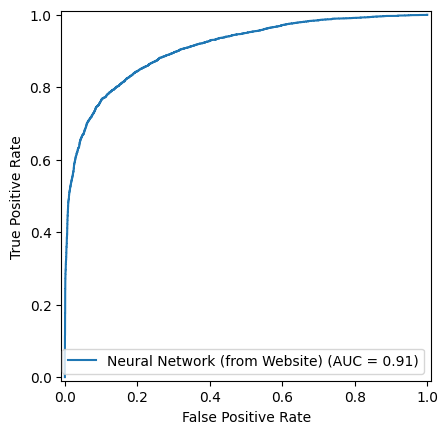

In [ ]:
y_prob = model(X_test)

fpr, tpr, thresholds = roc_curve(y_test.numpy(), y_prob.detach().numpy())

roc_auc = auc(fpr, tpr)

print(roc_auc)

display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="Neural Network (from Website)")
display.plot()

plt.show()

In [7]:
torch.manual_seed(124)

model = nn.Sequential(
    nn.Linear(25, 100),
    nn.ReLU(),
    nn.Linear(100, 80),
    nn.ReLU(),
    nn.Linear(80, 20),
    nn.ReLU(),
    nn.Linear(20, 1),
    nn.Sigmoid()
)

model

Sequential(
  (0): Linear(in_features=25, out_features=100, bias=True)
  (1): ReLU()
  (2): Linear(in_features=100, out_features=80, bias=True)
  (3): ReLU()
  (4): Linear(in_features=80, out_features=20, bias=True)
  (5): ReLU()
  (6): Linear(in_features=20, out_features=1, bias=True)
  (7): Sigmoid()
)

tensor([0.4610])
tensor([0.4761])
tensor([0.4657])
tensor([0.4702])
tensor([0.4659])
tensor([0.4704])
tensor([0.4768])
tensor([0.4963])
tensor([0.4579])
tensor([0.4654])


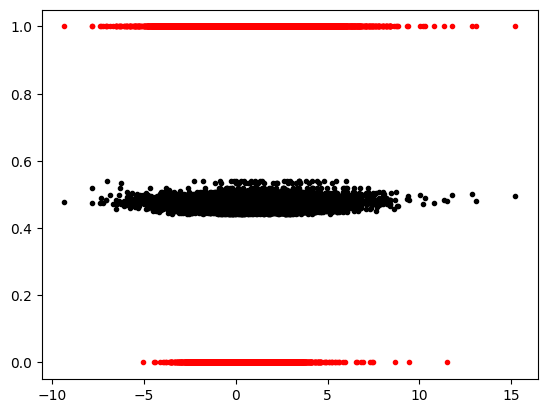

In [8]:
y_pred = model(X_test).detach()

for i in range(10):
    print(y_pred[i])
    
plt.plot(X_test.numpy(), y_pred.numpy(), 'k.')
plt.plot(X_test.numpy(), y_test.numpy(), 'r.')

In [9]:
loss_fn = nn.BCELoss() # binary cross entropy
# optimizer = optim.Adam(model.parameters(), lr=0.001)
optimizer = optim.Adam(model.parameters())
# optimizer = optim.SGD(model.parameters())

Finished epoch 0, latest loss 0.41097599267959595, 0.3811211884021759
Finished epoch 1, latest loss 0.39528003334999084, 0.3807537257671356


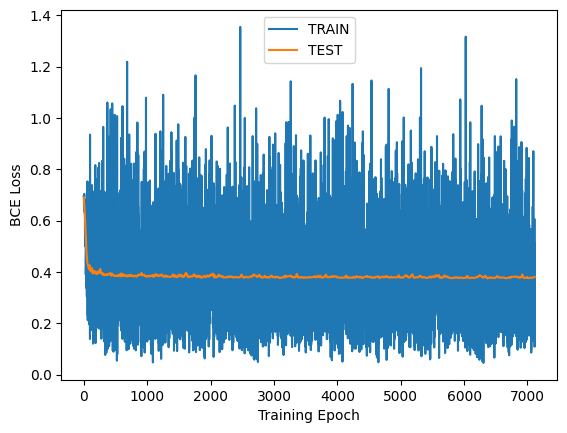

In [10]:
n_epochs = 1
batch_size = 10
lossesTrain = []
lossesTest = []

for epoch in range(n_epochs):
    for i in range(0, len(X_train), batch_size):
        model.train()
        Xbatch = X_train[i:i+batch_size]
        # Xbatch = X
        ybatch = y_train[i:i+batch_size]
        # ybatch = y
        y_prediction = model(Xbatch)
        loss = loss_fn(y_prediction, ybatch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        model.eval()
        y_pred = model(X_test)
        lossTest = loss_fn(y_pred, y_test)

        lossesTrain.append(loss.detach().numpy())
        lossesTest.append(lossTest.detach().numpy())

    print(f"Finished epoch {epoch}, latest loss {loss}, {lossTest}")

plt.plot(lossesTrain, label="TRAIN")
plt.plot(lossesTest, label="TEST")
plt.legend()
plt.xlabel("Training Epoch")
plt.ylabel("BCE Loss")
plt.show()

In [11]:
# compute accuracy (no_grad is optional)
with torch.no_grad():
    y_prediction = model(X_train)

accuracy = (y_prediction.round() == y_train).float().mean()
print(f"Accuracy (train) {accuracy}")

Accuracy (train) 0.8352445363998413


In [12]:
# compute accuracy (no_grad is optional)
with torch.no_grad():
    y_prediction = model(X_test)

for i in range(20):
    print(y_test[i], y_prediction[i])

accuracy = (y_prediction.round() == y_test).float().mean()
print(f"Accuracy (test) {accuracy}")

tensor([0.]) tensor([0.1816])
tensor([1.]) tensor([0.9983])
tensor([1.]) tensor([0.9995])
tensor([1.]) tensor([0.9670])
tensor([0.]) tensor([0.0522])
tensor([1.]) tensor([0.8742])
tensor([1.]) tensor([0.9957])
tensor([1.]) tensor([1.0000])
tensor([1.]) tensor([0.7915])
tensor([1.]) tensor([0.9880])
tensor([1.]) tensor([0.0871])
tensor([1.]) tensor([0.2061])
tensor([0.]) tensor([0.1577])
tensor([1.]) tensor([0.5377])
tensor([1.]) tensor([1.0000])
tensor([0.]) tensor([0.8252])
tensor([0.]) tensor([0.0933])
tensor([0.]) tensor([0.2116])
tensor([1.]) tensor([0.9342])
tensor([1.]) tensor([0.9916])
Accuracy (test) 0.8295109868049622


0.9086510528085678


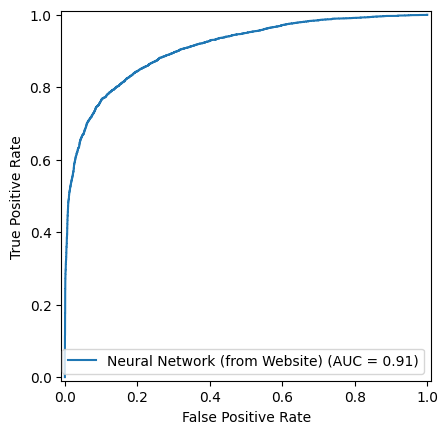

In [14]:
y_prob = model(X_test)

fpr, tpr, thresholds = roc_curve(y_test.numpy(), y_prob.detach().numpy())

roc_auc = auc(fpr, tpr)

print(roc_auc)

display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="Neural Network (from Website)")
display.plot()

plt.show()

### Neural Network (from Jupyter Notebook)

In [30]:
torch.manual_seed(123)
net = torch.nn.Sequential(
    torch.nn.Linear(10, 25),
    torch.nn.ReLU(),
    torch.nn.Linear(25, 25),
    torch.nn.ReLU(),
    torch.nn.Linear(25, 1),
    torch.nn.Sigmoid()
)

torch.save(net.state_dict(), 'net.pth')

In [1]:
y_pred = net(X_test).detach()

for i in range(10):
    print(y_pred[i])
    
plt.plot(X_test.numpy(), y_pred.numpy(), 'k.')
plt.plot(X_test.numpy(), y_test.numpy(), 'r.')

NameError: name 'net' is not defined

In [32]:
loss_fn = torch.nn.BCELoss()
optimizer = torch.optim.SGD(net.parameters(), lr=0.1, momentum=0.9)

/var/folders/4h/btz0vs815bgflhf3shpm_mwr0000gn/T/ipykernel_47465/2252925472.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load('net.pth'))


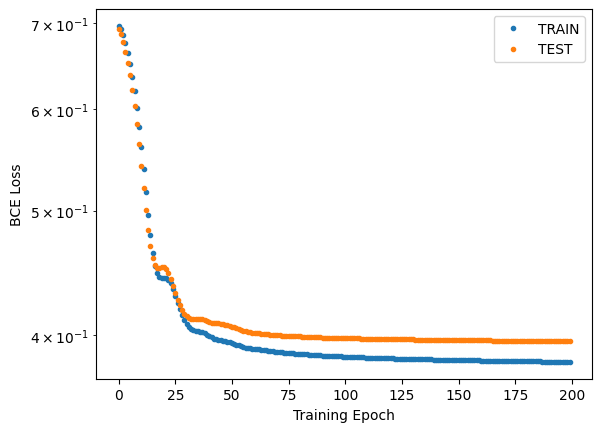

In [35]:
torch.manual_seed(123)
net.load_state_dict(torch.load('net.pth'))
losses_train, losses_test = [], []
for epoch in range(200):
    # Calculate the loss on the training sample.
    net.train() # configure the model for training
    y_pred = net(X_train)
    loss = loss_fn(y_pred, y_train)
    # Update the parameters.
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    # Save the training loss after each epoch.
    losses_train.append(loss.data)
    # Calculate and save the test loss after each epoch.
    net.eval() # configure the model for evaluation (testing)
    y_pred = net(X_test)
    losses_test.append(loss_fn(y_pred, y_test).data)
plt.plot(losses_train, '.', label='TRAIN')
plt.plot(losses_test, '.', label='TEST')
plt.legend()
plt.xlabel('Training Epoch')
plt.ylabel('BCE Loss')
plt.yscale('log')

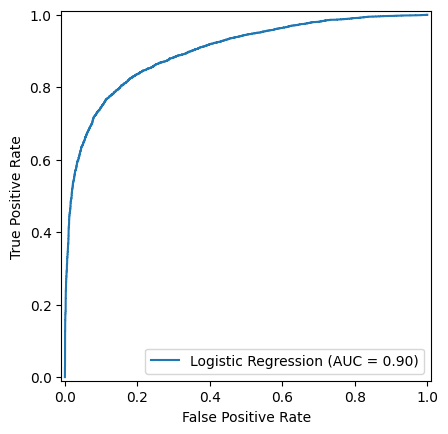

In [36]:
y_prob = net(X_test)

fpr, tpr, thresholds = roc_curve(y_test, y_prob.detach().numpy())

roc_auc = auc(fpr, tpr)

display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="Logistic Regression")
display.plot()

plt.show()

In [37]:
xy_train = torch.utils.data.TensorDataset(X_train, y_train)
loader = torch.utils.data.DataLoader(xy_train, batch_size=5, shuffle=True)

In [38]:
for batch_num, (x_batch, y_batch) in enumerate(loader):
    if batch_num < 2 or batch_num >= len(loader) - 2:
        print(f'BATCH {batch_num}:\n  x_batch[:,0] = {x_batch[:,0]}\n  y_batch[:,0] = {y_batch[:,0]}.')
    elif batch_num == 2:
        print('\n...\n')

BATCH 0:
  x_batch[:,0] = tensor([-0.1531, -1.0059, -0.1345, -0.7433, -0.9868])
  y_batch[:,0] = tensor([0., 0., 0., 0., 0.]).
BATCH 1:
  x_batch[:,0] = tensor([-0.5819, -0.2645, -0.8315, -0.0619, -0.3527])
  y_batch[:,0] = tensor([1., 0., 0., 1., 1.]).

...

BATCH 7114:
  x_batch[:,0] = tensor([ 0.2972, -0.8731, -0.9136,  1.2857, -0.0186])
  y_batch[:,0] = tensor([0., 0., 0., 1., 0.]).
BATCH 7115:
  x_batch[:,0] = tensor([-0.8143, -0.7175,  0.0139, -0.3021,  0.6193])
  y_batch[:,0] = tensor([0., 0., 1., 1., 1.]).


/var/folders/4h/btz0vs815bgflhf3shpm_mwr0000gn/T/ipykernel_47465/1350908684.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load('net.pth'))


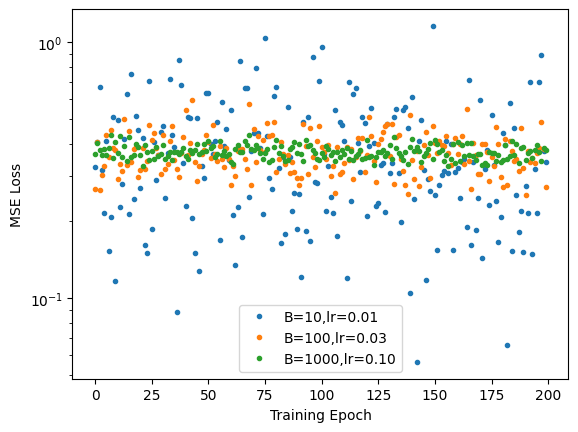

In [39]:
torch.manual_seed(123)
net.train()
for batch_size, learning_rate in zip((10, 100, 1000), (0.01, 0.03, 0.1)):
    optimizer = torch.optim.SGD(net.parameters(), lr=learning_rate, momentum=0.9)
    net.load_state_dict(torch.load('net.pth'))
    loader = torch.utils.data.DataLoader(xy_train, batch_size=batch_size, shuffle=True)
    losses = []
    for epoch in range(200):
        for x_batch, y_batch in loader:
            y_pred = net(x_batch)
            optimizer.zero_grad()
            loss = loss_fn(y_pred, y_batch)
            loss.backward()
            optimizer.step()
        losses.append(loss.data)
    plt.plot(losses, '.', label=f'B={batch_size},lr={learning_rate:.2f}')
plt.legend()
plt.xlabel('Training Epoch')
plt.ylabel('MSE Loss')
plt.yscale('log')

### Neural Network (from SKlearn)

In [40]:
netSKlearn = MLPClassifier(random_state=123)

netSKlearn.fit(X_train_numpy, y_train_numpy)

/Users/krishwu/.local/share/virtualenvs/WhitesonAIModelDistinguisher-zmfe64jY/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:1105: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Users/krishwu/.local/share/virtualenvs/WhitesonAIModelDistinguisher-zmfe64jY/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(random_state=123)

In [41]:
y_pred = netSKlearn.predict(X_test_numpy)

acc = accuracy_score(y_test_numpy, y_pred)
print("Neural Network model accuracy (in %):", acc)

Neural Network model accuracy (in %): 0.8270657672849916


In [42]:
confusion_matrix(y_test_numpy, y_pred)

array([[5126,  780],
       [1271, 4683]])

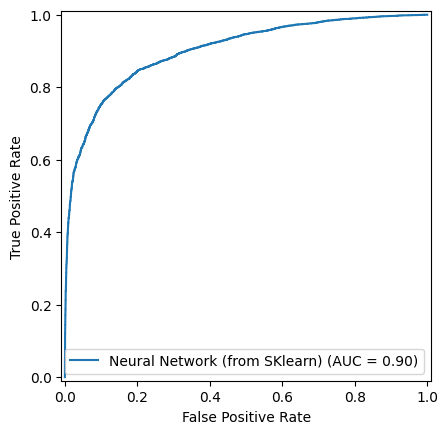

In [43]:
y_prob = netSKlearn.predict_proba(X_test_numpy)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test_numpy, y_prob)

roc_auc = auc(fpr, tpr)

display = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name="Neural Network (from SKlearn)")
display.plot()

plt.show()